# Fashion-MNIST: Logistic Regression baseline

**Krishna Gehlot · Milestone 3 · Team T112**
*Project 11: Inventory Image Tagging via Handcrafted Features and a Small CNN*

Model 1 of the Phase 1 AML baseline. A multinomial Logistic Regression is trained on both feature sets from Milestone 2, **flattened pixels (784)** and **HOG descriptors (324)**. Each image's class scores are a linear function of its features, so the learned weights for pixels can be viewed directly as $28 \times 28$ images.

**Protocol (shared across all four models):**
1. Tune $C \in \{0.1, 1, 10\}$ on the stratified 48,000/12,000 development split (seed 42) and select by **validation macro F1**.
2. Refit the selected pipeline on all 60,000 training images.
3. Evaluate once on the official 10,000-image test set and export `reports/results/logreg_{pixels,hog}.json`.

The test set is not used for any choice in this notebook.

In [1]:
import json
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.exceptions import ConvergenceWarning

ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "pyproject.toml").is_file() and (p / "docs/team").is_dir()),
    None,
)
if ROOT is None:
    raise RuntimeError("Open this notebook from the repository root or notebooks/ directory.")
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

from aml.data import CLASS_NAMES, get_train_val_test_splits
from aml.evaluation import compute_metrics
from aml.features import get_features
from aml.models.logreg import (
    C_GRID, build_logreg_pipeline, evaluate_final_logreg, make_result_record,
    save_result, tune_logreg,
)

# Fail loudly instead of reporting a model that stopped before converging.
warnings.simplefilter("error", ConvergenceWarning)

CACHE_DIR = ROOT / "data" / "cache"
RESULTS_DIR = ROOT / "reports" / "results"
FIGURES_DIR = ROOT / "reports" / "figures" / "logreg"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

FEATURE_LABELS = {"pixels": "Pixels", "hog": "HOG"}
SERIES_COLORS = {"pixels": "#2a78d6", "hog": "#eb6834"}
plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False})
print("Project root:", ROOT)

Project root: /Users/vipulsharma/Desktop/Image-Tagging


## 1. Load splits and cached features

Features come from `aml.features.get_features`. The first run extracts them and writes `data/cache/*.npz`; later runs load the cache. HOG extraction for all 130,000 images takes about a minute.

In [2]:
splits = get_train_val_test_splits(data_dir=ROOT / "data" / "raw")
y_train, y_val = splits["y_train"], splits["y_val"]
y_train_full, y_test = splits["y_train_full"], splits["y_test"]

features = {}
for kind in FEATURE_LABELS:
    features[kind] = {
        split: get_features(splits[f"X_{split}"], kind, CACHE_DIR / f"{split}_{kind}.npz")
        for split in ("train", "val", "test", "train_full")
    }
    shapes = ", ".join(f"{split} {X.shape}" for split, X in features[kind].items())
    print(f"{FEATURE_LABELS[kind]:>6}: {shapes}")

Pixels: train (48000, 784), val (12000, 784), test (10000, 784), train_full (60000, 784)


   HOG: train (48000, 324), val (12000, 324), test (10000, 324), train_full (60000, 324)


## 2. Tune the regularization strength $C$

The pipeline standardizes each feature (scaler fitted on the training split only) and fits a softmax classifier with an L2 penalty:

$$P(y = k \mid \mathbf{x}) = \frac{\exp(\mathbf{w}_k^\top \mathbf{x} + b_k)}{\sum_{j=0}^{9} \exp(\mathbf{w}_j^\top \mathbf{x} + b_j)}, \qquad
\min_{W,\,\mathbf{b}} \; \tfrac{1}{2}\lVert W \rVert_2^2 \;+\; C \sum_{i} -\log P(y_i \mid \mathbf{x}_i)$$

Smaller $C$ means stronger regularization (smaller weights). Every candidate is fitted with `lbfgs` and `max_iter=2000`. The team guide suggested 1000, but on pixels lbfgs needs about 1,100 iterations at $C=1$ and 1,260 at $C=10$. A `ConvergenceWarning` stops the notebook, so every reported model has converged.

In [3]:
tuning, best_C = {}, {}
for kind in FEATURE_LABELS:
    X = features[kind]
    print(f"--- {FEATURE_LABELS[kind]} ---")
    best_C[kind], tuning[kind] = tune_logreg(X["train"], y_train, X["val"], y_val, c_grid=C_GRID)

tuning_table = pd.DataFrame([{
    "Features": FEATURE_LABELS[kind],
    "C": result["C"],
    "Val Accuracy": result["val_accuracy"],
    "Val Macro F1": result["val_macro_f1"],
    "lbfgs Iterations": result["n_iter"],
    "Fit Time (s)": result["fit_seconds"],
    "Selected": "✓" if result["C"] == best_C[kind] else "",
} for kind in FEATURE_LABELS for result in tuning[kind]])
display(tuning_table.style.format({
    "C": "{:g}", "Val Accuracy": "{:.2%}", "Val Macro F1": "{:.2%}", "Fit Time (s)": "{:.1f}",
}).hide(axis="index"))
for kind in FEATURE_LABELS:
    print(f"Selected C for {FEATURE_LABELS[kind]}: {best_C[kind]:g}")

--- Pixels ---
Fitting Logistic Regression with C=0.1...


Fitting Logistic Regression with C=1.0...


Fitting Logistic Regression with C=10.0...


--- HOG ---
Fitting Logistic Regression with C=0.1...


Fitting Logistic Regression with C=1.0...


Fitting Logistic Regression with C=10.0...


Features,C,Val Accuracy,Val Macro F1,lbfgs Iterations,Fit Time (s),Selected
Pixels,0.1,85.97%,85.91%,779,14.5,✓
Pixels,1,85.05%,85.00%,1089,22.6,
Pixels,10,84.46%,84.39%,1257,26.3,
HOG,0.1,85.51%,85.49%,256,3.1,✓
HOG,1,85.23%,85.21%,452,5.2,
HOG,10,85.12%,85.10%,637,6.8,


Selected C for Pixels: 0.1
Selected C for HOG: 0.1


## 3. Refit on 60,000 images and evaluate on the test set

The selected $C$ for each feature set is refitted on the full official training set. Latency is the median per-image `predict()` time on a 1,000-image batch, including the scaler. Feature extraction is excluded, matching the team protocol. Parameter count is weights plus intercepts: $d \times 10 + 10$.

In [4]:
pipelines, test_metrics, records = {}, {}, {}
for kind in FEATURE_LABELS:
    X = features[kind]
    pipelines[kind], test_metrics[kind], latency_ms, param_count = evaluate_final_logreg(
        X["train_full"], y_train_full, X["test"], y_test, best_C[kind],
    )
    records[kind] = make_result_record(
        kind, best_C[kind], tuning[kind], test_metrics[kind], latency_ms, param_count,
        train_n=len(y_train), val_n=len(y_val), test_n=len(y_test),
    )
    print(f"Saved {save_result(records[kind], RESULTS_DIR).relative_to(ROOT)}")

summary = pd.DataFrame([{
    "Features": FEATURE_LABELS[kind],
    "Best C": r["best_params"]["C"],
    "Val Accuracy": r["validation_accuracy"],
    "Val Macro F1": r["validation_macro_f1"],
    "Test Accuracy": r["test_accuracy"],
    "Test Macro F1": r["test_macro_f1"],
    "Parameters": r["parameter_count"],
    "Latency (ms/img)": r["inference_latency_ms_per_image"],
} for kind, r in records.items()])
display(summary.style.format({
    "Best C": "{:g}", "Val Accuracy": "{:.2%}", "Val Macro F1": "{:.2%}", "Test Accuracy": "{:.2%}",
    "Test Macro F1": "{:.2%}", "Parameters": "{:,}", "Latency (ms/img)": "{:.4f}",
}).hide(axis="index"))

Saved reports/results/logreg_pixels.json


Saved reports/results/logreg_hog.json


Features,Best C,Val Accuracy,Val Macro F1,Test Accuracy,Test Macro F1,Parameters,Latency (ms/img)
Pixels,0.1,85.97%,85.91%,84.32%,84.24%,"7,850",0.0007
HOG,0.1,85.51%,85.49%,84.55%,84.49%,"3,250",0.0004


### Per-class test recall

Recall is the fraction of each garment's test images that the model labels correctly. Classes are listed top to bottom in label order.

,Pixels,HOG
T-shirt/top,80.6%,80.6%
Trouser,95.8%,94.8%
Pullover,73.7%,73.0%
Dress,86.1%,85.2%
Coat,76.0%,75.5%
Sandal,92.1%,93.3%
Shirt,57.1%,57.8%
Sneaker,93.8%,92.7%
Bag,93.2%,97.2%
Ankle boot,94.8%,95.4%


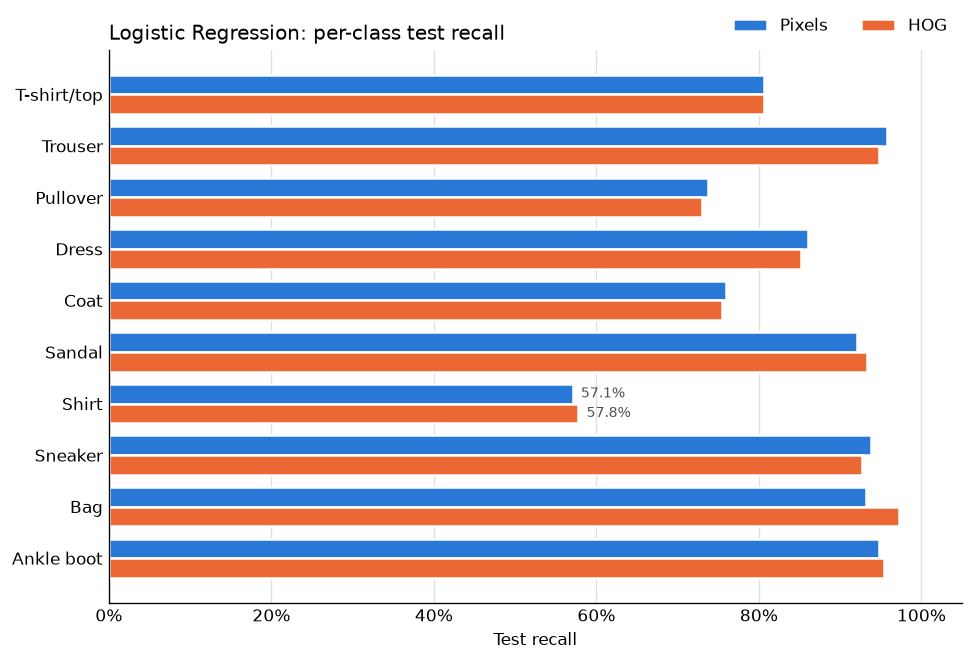

In [5]:
recall = pd.DataFrame(
    {FEATURE_LABELS[kind]: records[kind]["per_class_recall"] for kind in FEATURE_LABELS},
    index=CLASS_NAMES,
)
display(recall.style.format("{:.1%}"))

y_pos = np.arange(len(CLASS_NAMES))
height = 0.38
fig, ax = plt.subplots(figsize=(8, 5.4), constrained_layout=True)
for offset, kind in zip((-height / 2, height / 2), FEATURE_LABELS):
    ax.barh(y_pos + offset, recall[FEATURE_LABELS[kind]], height=height,
            color=SERIES_COLORS[kind], edgecolor="white", linewidth=1.5,
            label=FEATURE_LABELS[kind])

# Label only the weakest class, the comparison this chart exists to show.
weakest = int(recall.mean(axis=1).to_numpy().argmin())
for offset, kind in zip((-height / 2, height / 2), FEATURE_LABELS):
    value = recall.iloc[weakest][FEATURE_LABELS[kind]]
    ax.text(value + 0.01, weakest + offset, f"{value:.1%}", va="center",
            fontsize=8.5, color="#52514e")

ax.set_yticks(y_pos, CLASS_NAMES)
ax.invert_yaxis()
ax.set(xlim=(0, 1.05), xlabel="Test recall")
ax.set_title("Logistic Regression: per-class test recall", loc="left")
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.grid(axis="x", color="#e1e0d9", linewidth=0.8)
ax.set_axisbelow(True)
ax.tick_params(length=0)
ax.legend(ncols=2, frameon=False, loc="lower right", bbox_to_anchor=(1, 1))
fig.savefig(FIGURES_DIR / "per_class_recall.png", bbox_inches="tight")
plt.show()

The largest off-diagonal entries of each test confusion matrix (true class → predicted class, image count) show where the errors concentrate. The full matrices are saved in the JSON reports as `test_confusion_matrix` for the cross-model error analysis.

In [6]:
for kind in FEATURE_LABELS:
    cm = np.asarray(records[kind]["test_confusion_matrix"])
    errors = cm - np.diag(np.diag(cm))
    top = [divmod(int(flat), 10) for flat in np.argsort(errors, axis=None)[::-1][:6]]
    print(f"{FEATURE_LABELS[kind]}:")
    for true, pred in top:
        print(f"  {CLASS_NAMES[true]:>11} → {CLASS_NAMES[pred]:<11} {errors[true, pred]:4d}")

Pixels:
        Shirt → T-shirt/top  138
     Pullover → Coat         125
        Shirt → Pullover     120
         Coat → Pullover     116
  T-shirt/top → Shirt        109
        Shirt → Coat         104
HOG:
        Shirt → T-shirt/top  151
     Pullover → Coat         134
         Coat → Pullover     117
        Shirt → Coat         114
     Pullover → Shirt        106
  T-shirt/top → Shirt        105


## 4. What the pixel weights learned

Row $k$ of the $10 \times 784$ coefficient matrix scores class $k$, so it can be reshaped into a $28 \times 28$ image. The weights act on **standardized** pixels: a weight is the change in the class's log-odds score when that pixel is one standard deviation brighter than average.

- **Red (positive):** brightness here is evidence *for* the class.
- **Blue (negative):** brightness here is evidence *against* it, usually because it is typical of a competing class.
- **Gray (≈ 0):** the pixel does not help, e.g. border pixels that are always black.

The figure has three rows:

1. **Class mean:** the average training image of each class, for reference.
2. **Selected model:** the weights of the reported pixel model (the $C$ chosen above, refitted on 60,000 images).
3. **Interpretation model ($C = 0.001$):** the same pipeline with 100× stronger regularization, fitted on the 48,000-image training split. It is used only to make the templates readable and contributes to no reported number. Its validation score is printed below so its accuracy cost is visible.

Each weight row uses its own symmetric color scale, clipped at the 99th percentile of $|w|$ so a few extreme weights do not wash out the rest. The *neighbour correlation* (correlation between horizontally adjacent weights) measures smoothness: near 1 means a smooth template, near 0 means pixel-to-pixel noise.

Selected model (C=0.1): validation macro F1 85.91%, neighbour correlation +0.14
Interpretation model (C=0.001): validation macro F1 85.69%, neighbour correlation +0.64


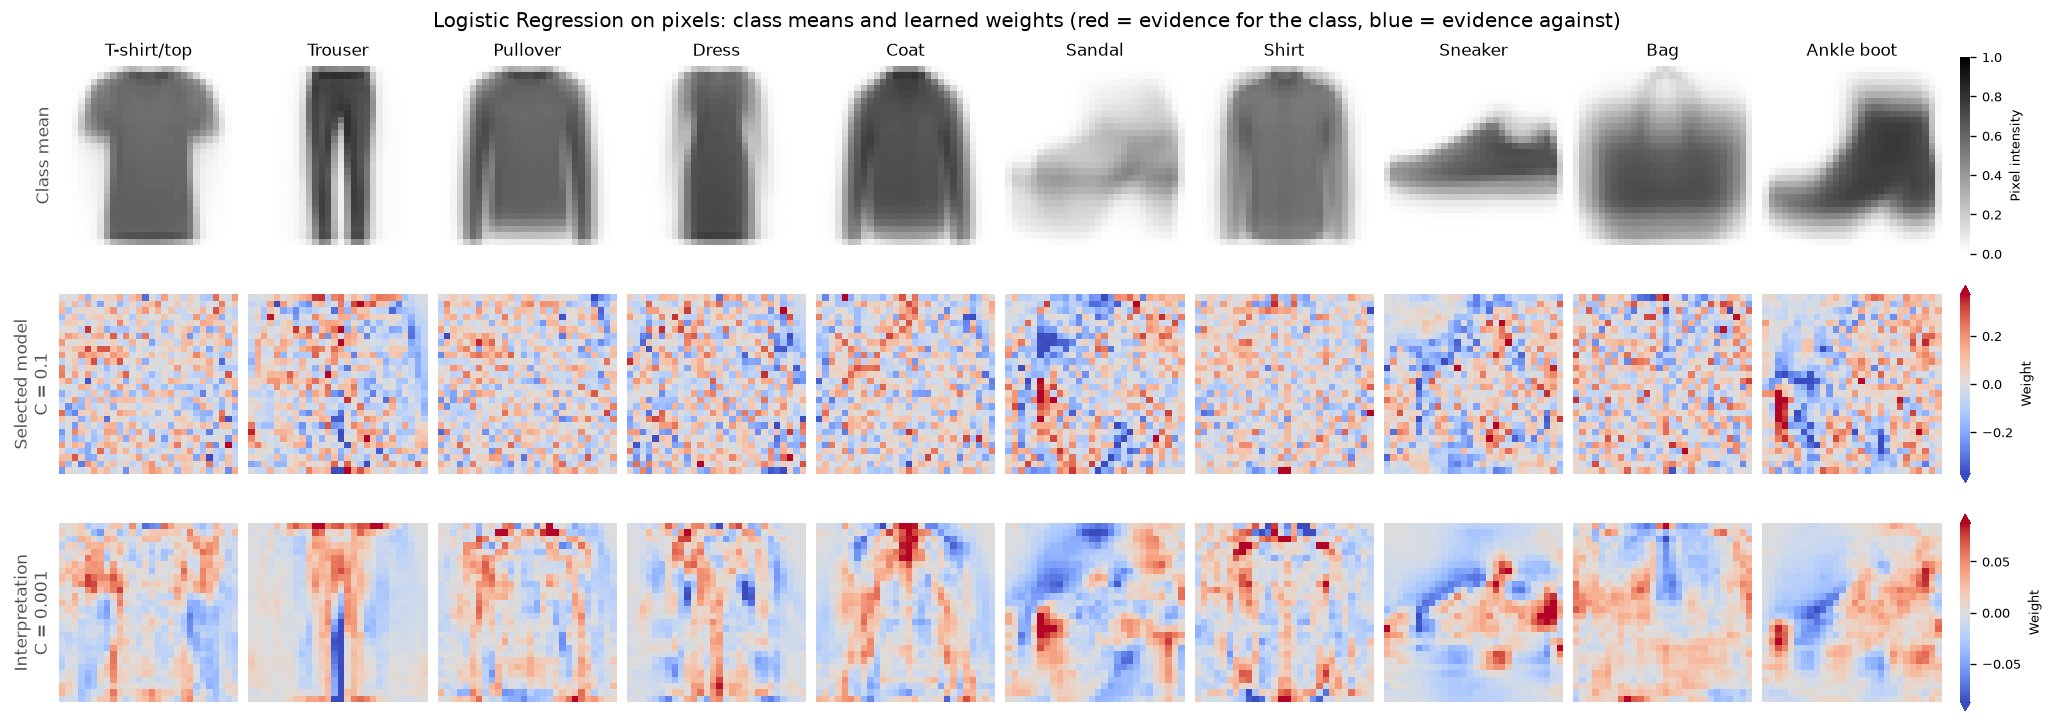

In [7]:
INTERPRET_C = 0.001
smooth_pipeline = build_logreg_pipeline(C=INTERPRET_C).fit(features["pixels"]["train"], y_train)
smooth_val = compute_metrics(y_val, smooth_pipeline.predict(features["pixels"]["val"]))

selected_coef = pipelines["pixels"].named_steps["model"].coef_
smooth_coef = smooth_pipeline.named_steps["model"].coef_
assert selected_coef.shape == smooth_coef.shape == (10, 784), selected_coef.shape
class_means = np.stack([splits["X_train_full"][y_train_full == k].mean(axis=0) for k in range(10)])


def neighbour_correlation(coef):
    weights = coef.reshape(10, 28, 28)
    return float(np.corrcoef(weights[:, :, :-1].ravel(), weights[:, :, 1:].ravel())[0, 1])


selected_val_f1 = records["pixels"]["validation_macro_f1"]
print(f"Selected model (C={best_C['pixels']:g}): validation macro F1 {selected_val_f1:.2%}, "
      f"neighbour correlation {neighbour_correlation(selected_coef):+.2f}")
print(f"Interpretation model (C={INTERPRET_C:g}): validation macro F1 {smooth_val['macro_f1']:.2%}, "
      f"neighbour correlation {neighbour_correlation(smooth_coef):+.2f}")

fig, axes = plt.subplots(3, 10, figsize=(17, 6), constrained_layout=True)
for k in range(10):
    image = axes[0, k].imshow(class_means[k], cmap="gray_r", vmin=0, vmax=1)
    axes[0, k].set_title(CLASS_NAMES[k], fontsize=10)
cbar = fig.colorbar(image, ax=axes[0, :].tolist(), shrink=0.9, pad=0.01)
cbar.set_label("Pixel intensity", fontsize=8)

for row, coef in ((1, selected_coef), (2, smooth_coef)):
    limit = float(np.percentile(np.abs(coef), 99))
    for k in range(10):
        heat = axes[row, k].imshow(coef[k].reshape(28, 28), cmap="coolwarm", vmin=-limit, vmax=limit)
    cbar = fig.colorbar(heat, ax=axes[row, :].tolist(), shrink=0.9, pad=0.01, extend="both")
    cbar.set_label("Weight", fontsize=8)

for row, label in enumerate(("Class mean", f"Selected model\nC = {best_C['pixels']:g}",
                             f"Interpretation\nC = {INTERPRET_C:g}")):
    axes[row, 0].set_ylabel(label, fontsize=10, color="#52514e")
for ax in axes.ravel():
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(False)
for cbar_ax in fig.axes[30:]:
    cbar_ax.tick_params(labelsize=8)
    cbar_ax.spines[:].set_visible(False)

fig.suptitle("Logistic Regression on pixels: class means and learned weights "
             "(red = evidence for the class, blue = evidence against)", fontsize=12)
fig.savefig(FIGURES_DIR / "pixel_weight_heatmaps.png", bbox_inches="tight")
plt.show()

### Reading the heatmaps

**The selected model's weights are mostly pixel-level noise** (neighbour correlation ≈ +0.14). Adjacent pixels in Fashion-MNIST are almost collinear. At $C = 0.1$ the penalty is weak relative to 48,000 training images, so the optimizer can give neighbouring pixels large weights of opposite sign that largely cancel on real images. Only the combined effect over a region carries meaning, so individual weights in this row should not be read as templates. The footwear classes and Trouser still show coarse structure, because their silhouettes differ from everything else by large regions.

**With 100× stronger regularization, the templates become readable** (neighbour correlation ≈ +0.64), and validation macro F1 falls only from 85.91% to 85.69%. The two models make almost the same decisions; the regularized one spreads its evidence smoothly instead of over offsetting pixel pairs:

- **Trouser:** red along both legs and a strong blue stripe in the gap between them. Brightness between the legs is evidence for a dress or a top.
- **T-shirt/top:** red where short sleeves sit at the shoulders and blue down the lower sides. Long sleeves there are what Pullover, Coat, and Shirt have and a T-shirt does not.
- **Pullover and Coat:** red outlines of the shoulders and long sleeves. Coat adds a strong red line down the top centre, where its collar and front opening sit.
- **Shirt:** red at the collar and along the edges of the torso. Its distinguishing evidence is a collar and placket, a small region compared with the shared torso.
- **Dress:** red vertical bands through a narrow body and blue on either side, where sleeves and arms of tops would be.
- **Sneaker and Ankle boot:** Sneaker is red on a low sole band and blue in an arc above it, where a boot shaft would be. Ankle boot is red over that tall shaft region.
- **Sandal:** mostly blue over areas a solid shoe would fill, with red only on scattered strap regions. Open, variable straps make it the least template-like footwear class.
- **Bag:** red across a wide body that reaches the corners, which no garment or shoe fills.

**Why this limits a linear model:** the four upper-body classes share nearly the entire torso template. They differ only in narrow regions (sleeve length, collar, front opening) whose exact pixel position varies from image to image. A single fixed weight per pixel cannot reliably detect a collar that may sit a few pixels higher or lower. This matches the error table above: every one of the six largest confusions, for both feature sets, is among T-shirt/top, Pullover, Coat, and Shirt.

## 5. Verify outputs

These checks match the team acceptance checklist and the master notebook's schema validator.

In [8]:
REQUIRED = {
    "model", "features", "best_params", "train_n", "val_n", "test_n",
    "validation_accuracy", "validation_macro_f1", "test_accuracy", "test_macro_f1",
    "per_class_recall", "parameter_count", "inference_latency_ms_per_image",
}
EXPECTED_PARAMS = {"pixels": 784 * 10 + 10, "hog": 324 * 10 + 10}

for kind in FEATURE_LABELS:
    saved = json.loads((RESULTS_DIR / f"logreg_{kind}.json").read_text())
    assert REQUIRED <= saved.keys(), REQUIRED - saved.keys()
    assert (saved["model"], saved["features"]) == ("logreg", kind)
    assert (saved["train_n"], saved["val_n"], saved["test_n"]) == (48000, 12000, 10000)
    assert all(0 <= saved[key] <= 1 for key in
               ("validation_accuracy", "validation_macro_f1", "test_accuracy", "test_macro_f1"))
    assert len(saved["per_class_recall"]) == 10
    assert all(0 <= value <= 1 for value in saved["per_class_recall"])
    assert saved["parameter_count"] == EXPECTED_PARAMS[kind]
    assert saved["inference_latency_ms_per_image"] > 0
    assert [r["C"] for r in tuning[kind]] == list(C_GRID)
    max_iter = pipelines[kind].named_steps["model"].max_iter
    assert all(r["n_iter"] < max_iter for r in tuning[kind]), "lbfgs hit max_iter"
    assert pipelines[kind].named_steps["model"].n_iter_.max() < max_iter

for name in ("pixel_weight_heatmaps.png", "per_class_recall.png"):
    assert (FIGURES_DIR / name).is_file(), name
print("All checks passed: both JSON reports match the schema, and every fit converged.")

All checks passed: both JSON reports match the schema, and every fit converged.


## 6. Summary

| | Pixels | HOG |
|---|---|---|
| Selected $C$ | 0.1 | 0.1 |
| Validation macro F1 | 85.91% | 85.49% |
| Test accuracy | 84.32% | 84.55% |
| Test macro F1 | 84.24% | 84.49% |
| Parameters | 7,850 | 3,250 |

- **Pixels vs HOG is effectively a tie for Logistic Regression.** Pixels is 0.4 points ahead on validation and HOG is 0.2 points ahead on test (about 23 test images). Neither gap is large enough to call a winner. HOG reaches the same accuracy with 41% of the parameters and lower latency. Pixels loses more from validation to test (−1.65 vs −0.96 points of accuracy).
- **Strongest regularization in the grid wins for both feature sets.** $C = 0.1$ is the lower edge of the agreed grid, so the optimum may lie slightly lower. The $C = 0.001$ interpretation model scores 85.69% validation macro F1 on pixels, so the optimum sits between 0.001 and 0.1, and any gain from a finer grid is small. The agreed grid is kept so all four models are tuned the same way.
- **Shirt is the weakest class** (57.1% recall on pixels, 57.8% on HOG). Shirts are most often predicted as T-shirt/top, Pullover, or Coat, and Pullover and Coat are frequently confused with each other. The weight templates show why: these garments differ only in small, position-variable details that a fixed per-pixel linear template cannot capture. This is the gap that Phase 2's CNN, with learned local and translation-tolerant filters, is meant to address.
- **Outputs:** `reports/results/logreg_pixels.json`, `reports/results/logreg_hog.json` (team schema plus `test_confusion_matrix`), `reports/figures/logreg/pixel_weight_heatmaps.png`, and `reports/figures/logreg/per_class_recall.png`.